In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

In [5]:
df = pd.read_csv("data/day.csv")
df["dteday"] = pd.to_datetime(df["dteday"])

In [6]:
y = df["cnt"]
X = df.drop(columns=["cnt", "casual", "registered"])

In [7]:
train = df[df["dteday"] < "2012-07-01"]
test = df[df["dteday"] >= '2012-07-01']

In [8]:
X_train = train.drop(columns=["cnt", "casual", "registered", "dteday"])
y_train = train["cnt"]
X_test = test.drop(columns=['cnt', 'casual', 'registered', 'dteday'])
y_test = test['cnt']

In [9]:
# modelling dummy baseline
from sklearn.dummy import DummyRegressor
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

In [10]:
# linear regression
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

In [15]:
# random forest
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [11]:
from xgboost import XGBRegressor
xgb = XGBRegressor(
    n_estimators=500,
    learning_rate = 0.05,
    max_depth = 6,
    random_state=42
)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

models = {
    "Dummy": y_pred_dummy,
    "Linear regression": y_pred_lr,
    "Random forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

results = []

for name, predictions in models.items():
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R²': r2
    })

results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,R²
0,Dummy,2452.640301,2694.302464,-1.394579
1,Linear regression,835.556617,1146.348387,0.566519
2,Random forest,849.619493,1077.848990,0.616776
3,XGBoost,916.705444,1145.729462,0.566987


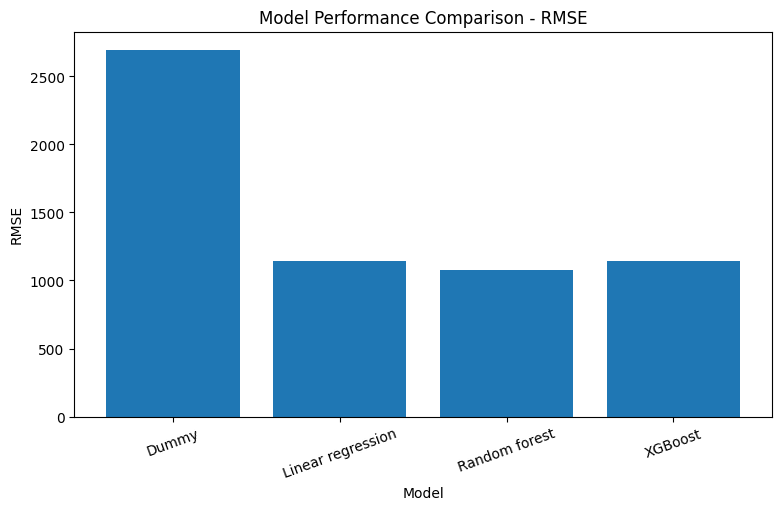

In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))

plt.bar(results_df['Model'], results_df['RMSE'])

plt.ylabel('RMSE')
plt.xlabel('Model')
plt.title('Model Performance Comparison - RMSE')
plt.xticks(rotation=20)
plt.show()

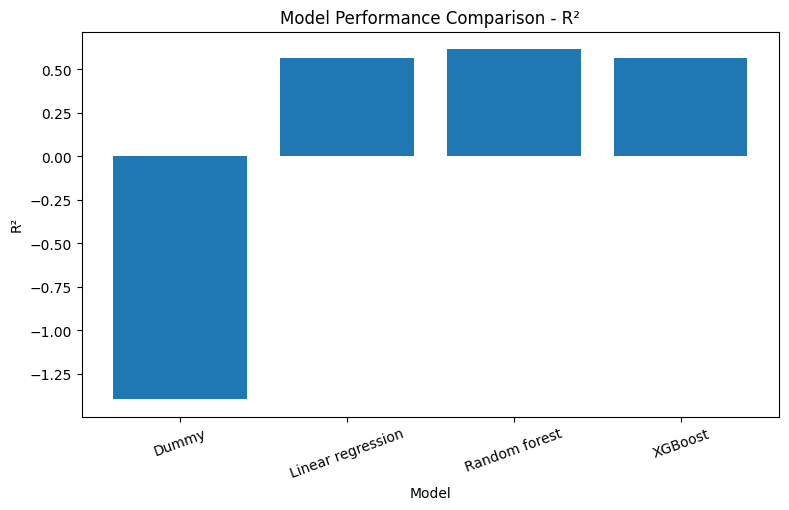

In [18]:
plt.figure(figsize=(9, 5))

plt.bar(results_df['Model'], results_df['R²'])

plt.ylabel('R²')
plt.xlabel('Model')
plt.title('Model Performance Comparison - R²')
plt.xticks(rotation=20)
plt.show()

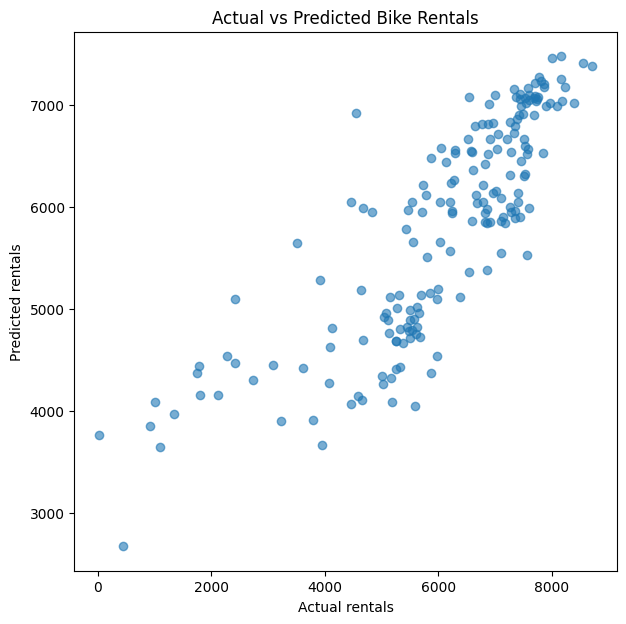

In [19]:
best_pred = y_pred_rf  # ak XGBoost vyhrá

plt.figure(figsize=(7, 7))

plt.scatter(y_test, best_pred, alpha=0.6)
plt.xlabel('Actual rentals')
plt.ylabel('Predicted rentals')
plt.title('Actual vs Predicted Bike Rentals')

plt.show()